# Project 1: VaR and ES -- Estimation, Backtesting, and Model Comparison

**Names of all group members:**
- Dario Frey (dario.frey@epfl.ch)
- Léo Wunderli (leo.wunderli@epfl.ch)
- Romain Fastenaekels (romain.fastenaekels@epfl.ch)
- Enzo Cassini-Peloux (enzo.cassini@epfl.ch)
---

## 0) Setup

Creates necessary folders, sets parameters, and fixes the random seed. Keep this seed fixed; the whole run must be reproducible from it.

In [1]:
# If a package import fails, install it in your environment, e.g.:
# %pip install arch statsmodels

import os
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path.cwd()
DATA_FILE = PROJECT_DIR / "QRM_2026_Project_prices.csv"   # provided with the project; do not re-download
OUT_DIR = PROJECT_DIR / "output"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Parameters
TICKERS = ["AAPL", "META", "JPM"]   # every question is run separately on each stock
WINDOW = 504                        # estimation window of every model, in trading days (Questions 2-5)
EVAL_START = 504                    # Questions 3-5: forecast days are all days after the first 504
REFIT = 21                          # Questions 4-5: re-estimate every this many trading days
ALPHAS = [0.975, 0.99]              # confidence levels used throughout Questions 2-5
DEEP_ALPHA = 0.999                  # Question 6: the extreme level EVT is asked for
M_SIM = 10_000                      # Questions 3(c), 4(d): Acerbi-Szekely simulated samples
LB_LAGS = 10                        # Ljung-Box H in Questions 1 and 4
NW_LAGS = 10                        # Newey-West truncation lag of the Diebold-Mariano test
SEED = 0                            # fix this, state it in the report, do not change it later

rng = np.random.default_rng(SEED)
print("Project dir:", PROJECT_DIR)


Project dir: /Users/dariofrey/Documents/Dario/Université/EPFL/MFE/MA-3/Quantitative Financial Risk Management/quant-risk-project


## 1) Data

The prices were downloaded once with `yfinance` (adjusted closes, 2 January 2013 to 30 June 2026,
downloaded on 28 October 2026) and are provided as `QRM_2026_Project_prices.csv`. Read this file;
do not download the data again, since Yahoo revises adjusted prices back in time.

In [2]:
price_df = pd.read_csv(DATA_FILE, index_col=0, parse_dates=True)[TICKERS]
print(price_df.shape, price_df.index[0].date(), "to", price_df.index[-1].date())   # (3393, 3)

(3393, 3) 2013-01-02 to 2026-06-30


## 2) Log-returns and losses

Construct $R_t=\log(P_t/P_{t-1})$ for each ticker. The log-loss used everywhere in this project is
$L_t=-R_t$. Every question is run separately on each of the three columns; there is no portfolio.

In [3]:
returns = np.log(price_df / price_df.shift(1)).dropna()
losses = -returns

print(returns.shape, returns.index[0].date(), "to", returns.index[-1].date())   # (3392, 3)
returns.head()

(3392, 3) 2013-01-03 to 2026-06-30


,AAPL,META,JPM
Date,,,
2013-01-03,-0.012703,-0.008248,-0.002017
2013-01-04,-0.028250,0.035029,0.017569
2013-01-07,-0.005900,0.022689,0.001101
2013-01-08,0.002688,-0.012312,0.001980
2013-01-09,-0.015752,0.051311,-0.000660


## Question 1 -- Stylized facts

For each stock: (a) plot the return series; (b) ACF of returns and of squared returns, and the
Ljung-Box test with $H$ = `LB_LAGS` on both (`statsmodels.stats.diagnostic.acorr_ljungbox`);
(c) QQ-plot and Jarque-Bera.

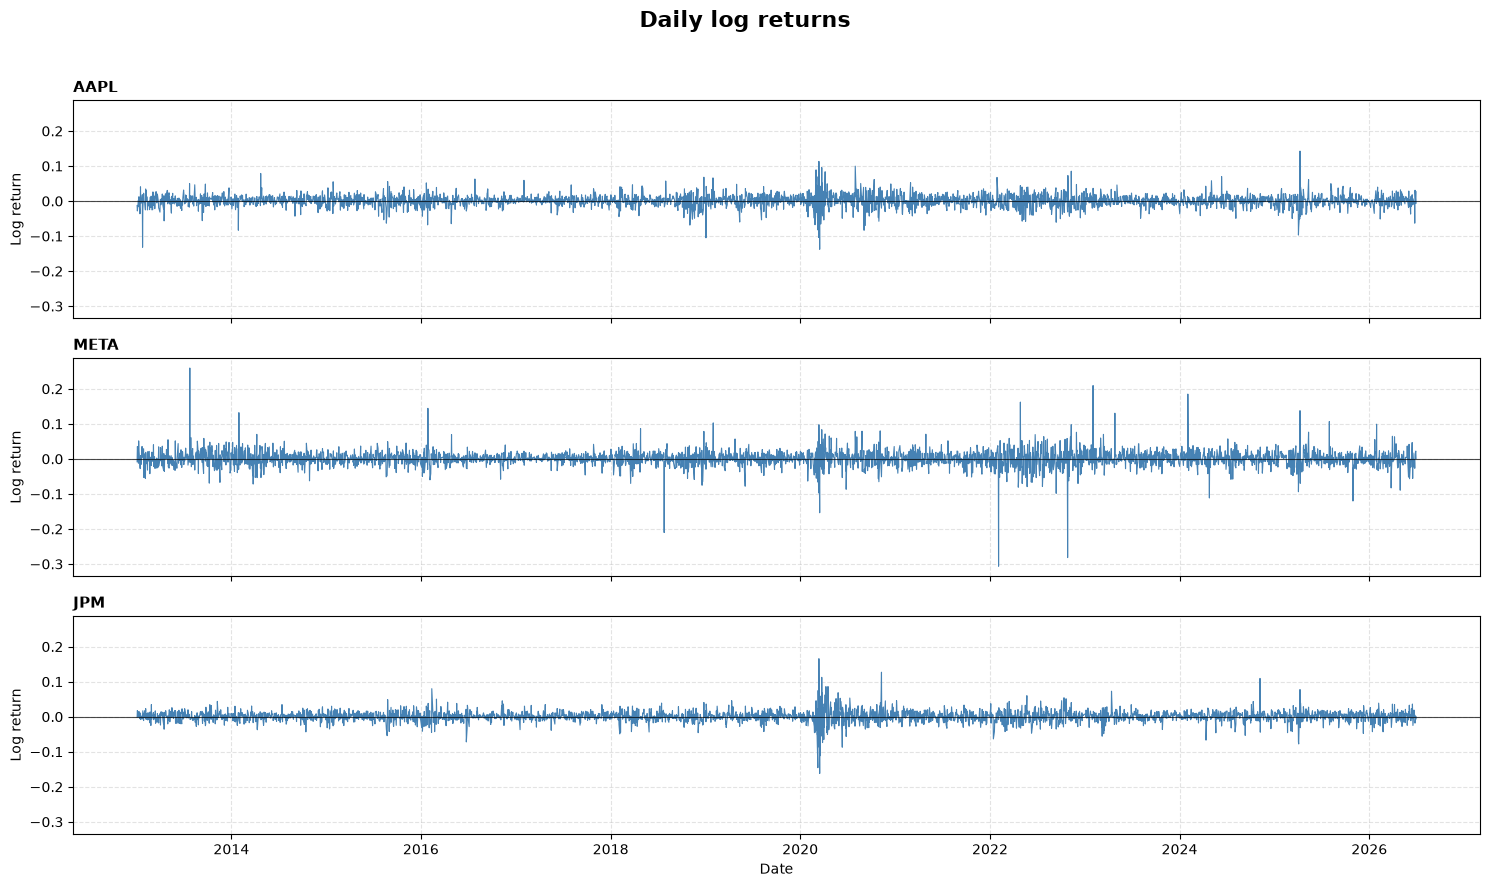

In [104]:
# Question 1

# (a)
n_series = len(returns.columns)
fig, axes = plt.subplots(
    n_series, 1,
    figsize=(15, 3 * n_series),
    sharex=True,
    sharey=True,
    squeeze=False,
)

fig.suptitle("Daily log returns", fontsize=16, fontweight="bold")

for ax, column in zip(axes[:, 0], returns.columns):
    ax.plot(returns.index, returns[column], linewidth=0.8, color="steelblue")
    ax.axhline(0, color="black", linewidth=0.8, alpha=0.7)
    ax.set_title(str(column), loc="left", fontsize=11, fontweight="bold")
    ax.set_ylabel("Log return")
    ax.grid(True, linestyle="--", alpha=0.35)

axes[-1, 0].set_xlabel("Date")
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

We observe common volatility spikes around the Covid-19 period (2020) even though JPM seems to be present the highest volatility. 
Each stock otherwise present signs of independent volatilty spikes. One interesting fact on this period (2013-2026) is the number of extreme events that happened with META. 

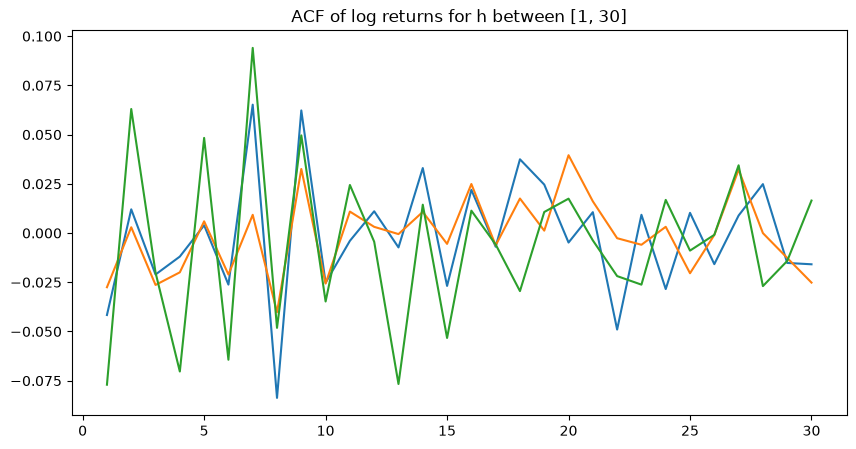

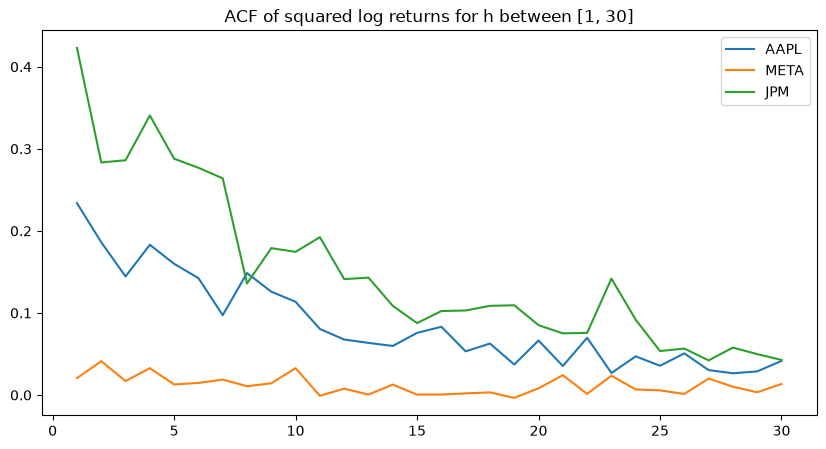

Ljung-box test - returns


,AAPL,META,JPM
lb_stat,6.443005e+01,19.576186,1.242931e+02
lb_pvalue,5.209219e-10,0.033526,6.791373e-22


Ljung-box test - squared returns


,AAPL,META,JPM
lb_stat,8.492934e+02,19.097453,2607.492719
lb_pvalue,5.179304e-176,0.039042,0.000000


In [ ]:
# (b)
# We use the statsmodels acf and acorr_ljungbox methods
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox

# Dict to store ACF values as well as qstat
ACF = {
    
}

ljung = {
    
}

ljung_squared = {
    
}

for elem in returns:
    ret = returns[elem]
    ret_2 = returns[elem] ** 2
    
    # Ljung-box test
    lj1 = acorr_ljungbox(ret, lags=[10])
    lj2 = acorr_ljungbox(ret_2, lags=[10])
    ljung[elem] = lj1.values.reshape(-1, )
    ljung_squared[elem] = lj2.values.reshape(-1, )
    
    # acf returns an object on which following method can be used : 
    # acf_object.qstat
    # acf_object.acf
    
    acf_ret = acf(ret, qstat = True, nlags = 30, result_object = True)
    acf_ret_2 = acf(ret_2, qstat = True, nlags = 30, result_object = True)
    
    ACF[elem] = [acf_ret, acf_ret_2]
    
# We now plot the acf values for log returns
fig1, ax1 = plt.subplots(figsize=(10, 5))
fig2, ax2 = plt.subplots(figsize=(10, 5))
for name, value in ACF.items():
    
    # Get Y data
    val1 = value[0].acf
    val2 = value[1].acf
    
    # Get X data
    h = np.arange(1, 31, 1)
    
    # plot
    ax1.plot(h, val1[1:], label = name)
    ax2.plot(h, val2[1:], label = name)
    
    
    
ax1.set(
    title = 'ACF of log returns for h between [1, 30]'
)
ax2.set(
    title = 'ACF of squared log returns for h between [1, 30]'
)

plt.legend()
plt.show()
  
# Display Ljung-Box test
    
print('Ljung-box test - returns')
display(pd.DataFrame(ljung, index=['lb_stat', 'lb_pvalue']))
print('Ljung-box test - squared returns')
display(pd.DataFrame(ljung_squared, index=['lb_stat', 'lb_pvalue']))


The Ljung-Box test evaluate the H0 hypothesis that the autocorrelation is null. In other word, high `lb_stat`or low `lb_pvalue` reject the H0 hypothesis and the data is showing serial correlation.
We observe in the data that `META` is graphically showing no sign of serial correlation while `JPM` and `AAPL` show a form of serial correlation. The lb_pvalue for all three stock allow to reject at the 0.05 level the H0 hypothesis for both returns and squared returns.

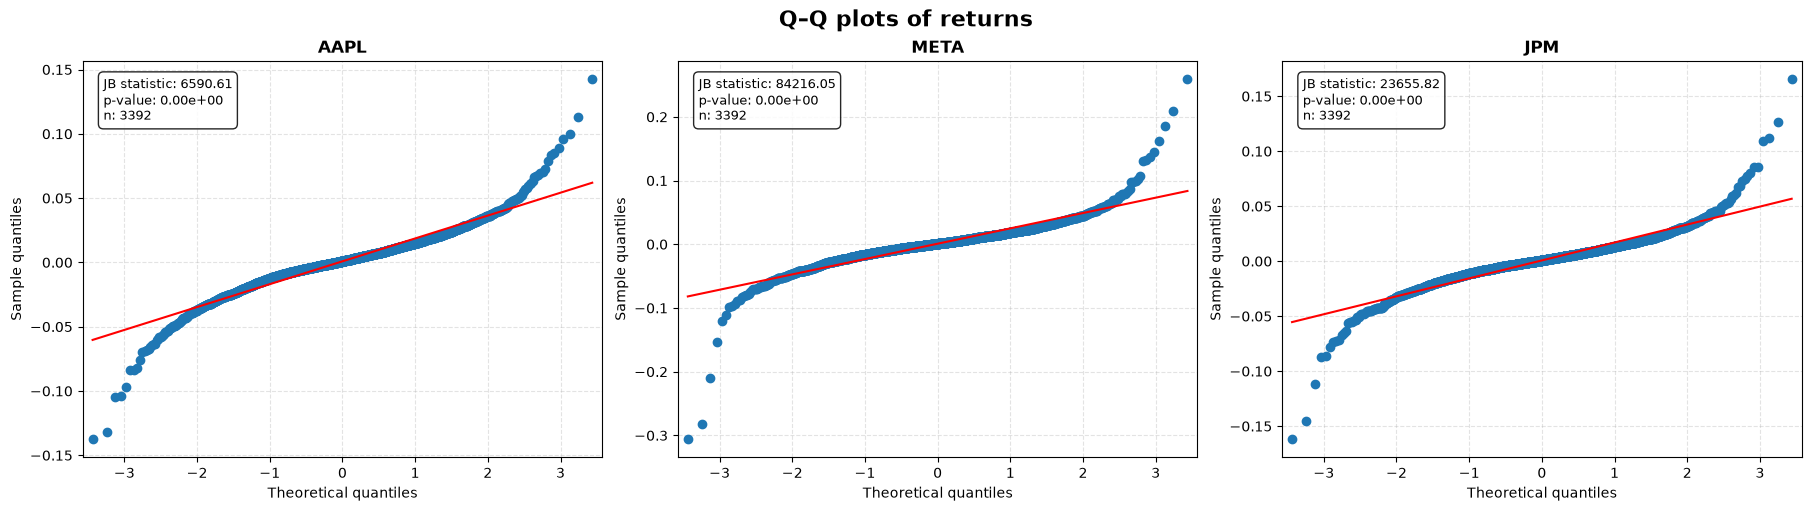

In [ ]:
# (c) 
# 1. Q-Q plot
from statsmodels.graphics.gofplots import qqplot
from statsmodels.stats.stattools import jarque_bera

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
fig.suptitle("Q–Q plots of returns", fontsize=16, fontweight="bold")

for ax, column in zip(axes, returns.columns):
    data = returns[column].dropna()
    jb_stat, jb_pvalue, skew, kurt = jarque_bera(data)

    qqplot(data, line="s", ax=ax)
    ax.set_title(column, fontsize=12, fontweight="bold")
    ax.set_xlabel("Theoretical quantiles")
    ax.set_ylabel("Sample quantiles")
    ax.grid(True, linestyle="--", alpha=0.35)

    ax.text(
        0.04, 0.96,
        f"JB statistic: {jb_stat:.2f}\n p-value: {jb_pvalue:.2e}\n n: {len(data)}",
        transform=ax.transAxes,
        va="top",
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.85),
    )

plt.show()


The null hypothesis is that the data is following a normal distribution. It is clear in this scenario that for the three stocks, H0 can be rejected at least at the 0.05 level. We can observe on the QQ-plot that the tails of the returns diverge heavily from a normal distribution. This is coherent with the heavy tail behavior of stock returns. 

## Question 2 -- Single-window VaR and ES estimates

For each stock, use the first `WINDOW` losses as the single estimation window for (a)-(d).

In [ ]:
# Question 2
window_loss = losses.iloc[:WINDOW]          # one column per stock


## Question 3 -- Backtesting

Forecast every day of the evaluation period `losses.iloc[EVAL_START:]`, each model estimated on the
`WINDOW` days before the forecast day. Historical simulation, Gaussian and Student-$t$ are recomputed
every day. Write the Kupiec, Christoffersen, Acerbi-Szekely, Fissler-Ziegel, pinball-loss and
Diebold-Mariano functions yourself, from the course slides (Kupiec, Christoffersen) and Appendix A of
the project statement (the others); they are
reused unchanged in Questions 4 and 5.

The combined VaR backtest table collects the VaR backtests of Questions 3-5: append one row per
stock, method and level to `backtest_rows` as you go. The ES backtest table ($\alpha=0.975$) collects
the Acerbi-Szekely and Fissler-Ziegel results of Questions 3 and 4 in `es_rows`.

In [ ]:
# Question 3
eval_loss = losses.iloc[EVAL_START:]        # one column per stock, 2888 forecast days
backtest_rows = []                          # dicts: stock, method, alpha, x, expected, hit, p_uc, p_ind, p_cc, pinball_bp
es_rows = []                                # dicts: stock, method, Z, p_Z, FZ


## Question 4 -- AR-GARCH conditional VaR and ES

(a) Mean model, full sample: fit AR($p$), $p=0,\dots,3$, with constant variance on the same
observations, e.g. `ARX(y, lags=p, hold_back=3)` from `arch.univariate`; pick $p$ by BIC (also report
AIC); Ljung-Box on the residuals (`model_df=p`) and on their squares.
(b) Fit `arch_model(y, mean="AR", lags=p, vol="GARCH", p=1, q=1, dist=..., hold_back=3)` on the full
sample with `dist="normal"` and `dist="t"` (use `mean="Constant"` if $p=0$); Ljung-Box on the
standardized residuals of the Gaussian fit (`model_df=p`) and their squares (`model_df=2`).
(c) Re-estimate both inside the rolling scheme every `REFIT` days with the same $p$. Between refits,
keep the parameters fixed but advance $\hat\mu_t$ and $\hat\sigma_t$ daily with the realized
returns (for example with `arch_model(...).fix(params)` on the data up to the forecast day). Fit on
returns in percent (`100 * R`) to avoid `arch` convergence warnings, and convert the forecasts back.
(d) Backtest both and add them to the two tables.

In [ ]:
# Question 4
from arch import arch_model


## Question 5 -- Quantile regression

Same evaluation period, window and refit days as Question 4. One model per stock and level, VaR only;
the two features are built by `make_features` below, both using information up to $t-1$; the target
is the loss $L_t$. Rows with an undefined feature (the first 20 days) are dropped from the training
window. Linear quantile regression, e.g.
`sm.QuantReg(y, sm.add_constant(X)).fit(q=alpha, max_iter=5000)`.

In [ ]:
# Question 5
import statsmodels.api as sm


def make_features(ret: pd.Series) -> pd.DataFrame:
    """Features x_{t-1} for the forecast of day t: row t uses information up to t-1 only."""
    feat = pd.DataFrame(index=ret.index)
    feat["absR_lag1"] = ret.shift(1).abs()
    feat["sigma20"] = ret.shift(1).rolling(20).std(ddof=1)
    return feat


# After (a) and (b): the combined VaR backtest table, one table per level
# backtest_table = pd.DataFrame(backtest_rows).set_index(["alpha", "stock", "method"]).sort_index()


## Question 6 -- Extreme value theory

One static fit on each stock's full-sample log-loss series, with threshold $u$ the empirical 95%
quantile. `scipy.stats.genpareto.fit(excesses, floc=0)` may be used for the GPD maximum-likelihood
step.

In [ ]:
# Question 6
from scipy.stats import genpareto
full_loss = losses                          # one column per stock
